# Análise e tratamento dos dados Home Credit
Análise exploratória descritiva das 32 variáveis da competição GCI.
Código em etapas, com pandas, numpy, matplotlib, scipy e scikit-learn.
Execute da pasta do projeto. Os originais ficam em input/.
Este trabalho prepara dados; não treina o ensemble nem produz previsões.

In [1]:
from pathlib import Path
import json
import hashlib
import html
import platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split

BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "input" / "train.csv").exists()), Path("/content/drive/MyDrive/Competition"))
if not (BASE / "input" / "train.csv").exists():
    raise FileNotFoundError("Execute da pasta GCI, que contém input/train.csv.")
REL = BASE / "analise"
FIG = REL / "graficos"
LIMPOS = BASE / "dados_tratados"
MODELO = BASE / "dados_modelagem"
for pasta in [REL, FIG, LIMPOS, MODELO]:
    pasta.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
train = pd.read_csv(BASE / "input" / "train.csv")
test = pd.read_csv(BASE / "input" / "test.csv")
sample = pd.read_csv(BASE / "input" / "sample_submission.csv")
features = train.columns.drop(["SK_ID_CURR", "TARGET"]).tolist()
numericas = train[features].select_dtypes(include="number").columns.tolist()
categoricas = train[features].select_dtypes(exclude="number").columns.tolist()
print("Treino:", train.shape, "Teste:", test.shape)
print("Variáveis numéricas:", len(numericas), "Categóricas:", len(categoricas))

Treino: (171202, 34) Teste: (61500, 33)
Variáveis numéricas: 24 Categóricas: 8


## 1. Integridade e rastreabilidade
Conferimos IDs, duplicatas, colunas, alvo e alinhamento da submissão.
Perfis iguais podem corresponder a clientes diferentes: não são excluídos.

In [2]:
assert train.columns.is_unique and test.columns.is_unique
assert train["SK_ID_CURR"].notna().all() and test["SK_ID_CURR"].notna().all()
assert train["SK_ID_CURR"].is_unique and test["SK_ID_CURR"].is_unique
assert train["TARGET"].notna().all() and set(train["TARGET"].unique()) == {0, 1}
assert set(test.columns) == set(train.columns) - {"TARGET"}
assert sample["SK_ID_CURR"].is_unique
assert sample["SK_ID_CURR"].tolist() == test["SK_ID_CURR"].tolist()
assert set(train["SK_ID_CURR"]).isdisjoint(test["SK_ID_CURR"])
manifesto = []
for nome in ["train.csv", "test.csv", "sample_submission.csv"]:
    caminho = BASE / "input" / nome
    manifesto.append({"arquivo": nome, "bytes": caminho.stat().st_size,
                      "sha256": hashlib.sha256(caminho.read_bytes()).hexdigest()})
pd.DataFrame(manifesto).to_csv(REL / "manifesto_originais.csv", index=False)
integridade = []
for nome, dados in [("treino", train), ("teste", test)]:
    integridade.append({"base": nome, "linhas": len(dados), "colunas": len(dados.columns),
        "ids_duplicados": int(dados["SK_ID_CURR"].duplicated().sum()),
        "linhas_identicas": int(dados.duplicated().sum()),
        "perfis_repetidos_sem_id_alvo": int(dados[features].duplicated().sum()),
        "valores_infinitos": int(np.isinf(dados[numericas]).sum().sum())})
integridade = pd.DataFrame(integridade)
integridade.to_csv(REL / "integridade.csv", index=False)
print(integridade.to_string(index=False))

  base  linhas  colunas  ids_duplicados  linhas_identicas  perfis_repetidos_sem_id_alvo  valores_infinitos
treino  171202       34               0                 0                             0                  0
 teste   61500       33               0                 0                             0                  0


## 2. Perfil de todas as colunas e ausências originais
Ausência não equivale a zero. Valores como XNA são examinados separadamente.
O arquivo perfil_colunas.csv cobre treino e teste, inclusive tipos e cardinalidade.

                            treino_pct  teste_pct
coluna                                           
EXT_SOURCE_1                     69.47      69.78
OWN_CAR_AGE                      66.00      66.52
EXT_SOURCE_3                     31.88      32.02
AMT_REQ_CREDIT_BUREAU_MON        13.50      13.84
AMT_REQ_CREDIT_BUREAU_QRT        13.50      13.84
AMT_REQ_CREDIT_BUREAU_YEAR       13.50      13.84
AMT_REQ_CREDIT_BUREAU_HOUR       13.50      13.84
EXT_SOURCE_2                      0.22       0.21
CNT_FAM_MEMBERS                   0.00       0.00
NAME_CONTRACT_TYPE                0.00       0.00
CNT_CHILDREN                      0.00       0.00
CODE_GENDER                       0.00       0.00


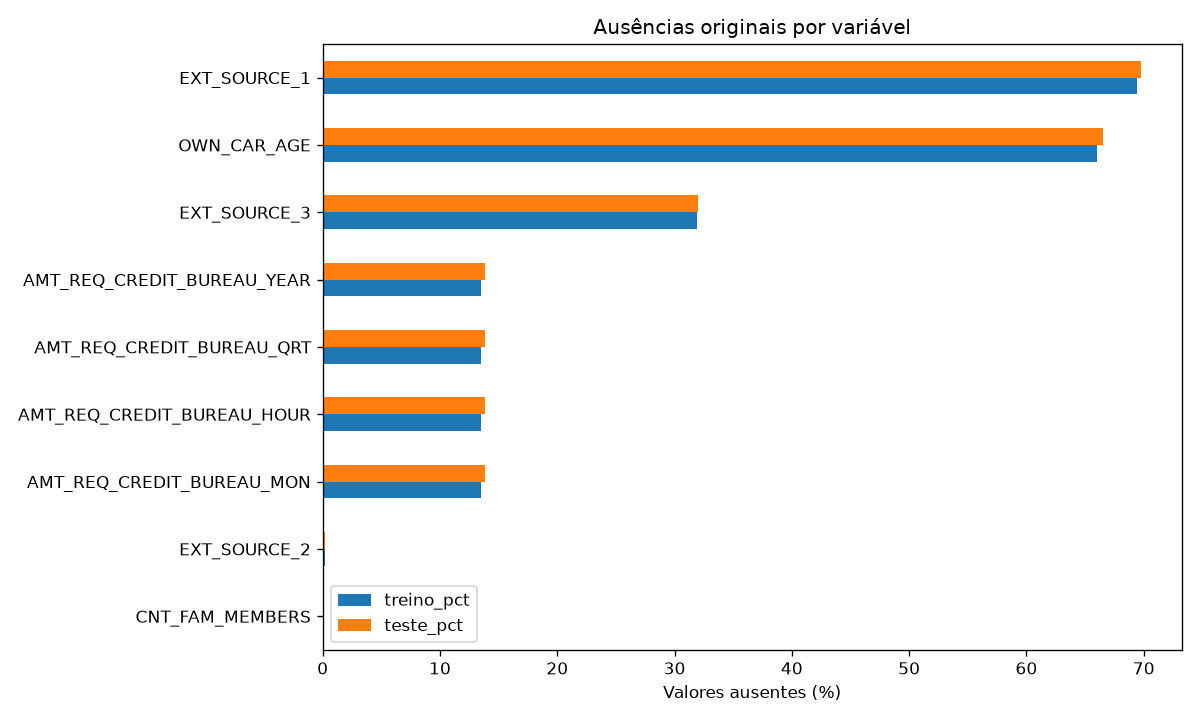

In [3]:
perfis = []
for nome, dados in [("treino", train), ("teste", test)]:
    for coluna in dados.columns:
        serie = dados[coluna]
        frequencias = serie.value_counts(dropna=False)
        perfis.append({"base": nome, "coluna": coluna, "tipo": str(serie.dtype),
            "ausentes": int(serie.isna().sum()), "ausentes_pct": serie.isna().mean() * 100,
            "distintos_sem_na": serie.nunique(),
            "mais_frequente": str(frequencias.index[0]),
            "mais_frequente_pct": frequencias.iloc[0] / len(serie) * 100})
perfil = pd.DataFrame(perfis)
perfil.to_csv(REL / "perfil_colunas.csv", index=False)
ausencias = pd.DataFrame({"treino_pct": train[features].isna().mean() * 100,
                          "teste_pct": test[features].isna().mean() * 100})
ausencias.index.name = "coluna"
ausencias.to_csv(REL / "ausencias_originais.csv")
print(ausencias.sort_values("treino_pct", ascending=False).head(12).round(2))
fig, ax = plt.subplots(figsize=(10, 6))
ausencias.loc[ausencias.max(axis=1).gt(0)].sort_values("treino_pct").plot.barh(ax=ax)
ax.set(xlabel="Valores ausentes (%)", ylabel="", title="Ausências originais por variável")
fig.tight_layout()
fig.savefig(FIG / "01_ausencias.png")
plt.close(fig)

## 3. Auditoria de valores suspeitos
Dias negativos indicam eventos anteriores ao pedido e são preservados.
DAYS_EMPLOYED = 365243 equivale a cerca de mil anos e será marcado como ausente.
Idade do carro >= 60 segue o tratamento sugerido pelo tutorial do curso.
Valores altos de renda/crédito serão sinalizados pelo IQR, mas preservados.
Não inferimos erro apenas porque um valor é raro ou extremo.

In [4]:
auditoria = []
for nome, dados in [("treino", train), ("teste", test)]:
    for coluna in features:
        serie = dados[coluna]
        regras = {}
        if coluna in categoricas:
            regras["marcador_XNA_XAP_Unknown"] = serie.isin(["XNA", "XAP", "Unknown"])
            regras["vazio_ou_espacos"] = serie.notna() & serie.astype(str).str.strip().eq("")
        if coluna == "DAYS_EMPLOYED":
            regras["sentinela_365243"] = serie.eq(365243)
            regras["dias_positivos_exceto_sentinela"] = serie.gt(0) & serie.ne(365243)
        if coluna.startswith("DAYS_") and coluna != "DAYS_EMPLOYED":
            regras["dias_positivos"] = serie.gt(0)
        if coluna == "OWN_CAR_AGE":
            regras["carro_60_anos_ou_mais"] = serie.ge(60)
        if coluna in numericas and not coluna.startswith("DAYS_"):
            regras["numero_negativo"] = serie.lt(0)
        if coluna in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
            regras["valor_monetario_nao_positivo"] = serie.le(0)
        if coluna.startswith("EXT_SOURCE_"):
            regras["score_fora_0_1"] = serie.lt(0) | serie.gt(1)
        if coluna.startswith("FLAG_"):
            regras["flag_fora_0_1"] = serie.notna() & ~serie.isin([0, 1])
        if coluna in ["CNT_CHILDREN", "CNT_FAM_MEMBERS", "OWN_CAR_AGE",
                      "AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_MON",
                      "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR"]:
            regras["contagem_fracionaria"] = serie.notna() & serie.mod(1).ne(0)
        for regra, mascara in regras.items():
            auditoria.append({"base": nome, "coluna": coluna, "regra": regra,
                              "quantidade": int(mascara.sum()), "pct": mascara.mean() * 100})
    auditoria.append({"base": nome, "coluna": "CNT_FAM_MEMBERS/CNT_CHILDREN",
        "regra": "familia_menor_que_filhos_mais_cliente",
        "quantidade": int((dados["CNT_FAM_MEMBERS"] < dados["CNT_CHILDREN"] + 1).sum()),
        "pct": float((dados["CNT_FAM_MEMBERS"] < dados["CNT_CHILDREN"] + 1).mean() * 100)})
    auditoria.append({"base": nome, "coluna": "DAYS_EMPLOYED/DAYS_BIRTH",
        "regra": "tempo_emprego_maior_que_idade",
        "quantidade": int((-dados["DAYS_EMPLOYED"] > -dados["DAYS_BIRTH"]).sum()),
        "pct": float((-dados["DAYS_EMPLOYED"] > -dados["DAYS_BIRTH"]).mean() * 100)})
auditoria = pd.DataFrame(auditoria)
auditoria.to_csv(REL / "auditoria_valores.csv", index=False)
print(auditoria.loc[auditoria.quantidade.gt(0)].to_string(index=False))

  base             coluna                    regra  quantidade       pct
treino        CODE_GENDER marcador_XNA_XAP_Unknown           4  0.002336
treino NAME_FAMILY_STATUS marcador_XNA_XAP_Unknown           2  0.001168
treino      DAYS_EMPLOYED         sentinela_365243       30898 18.047686
treino        OWN_CAR_AGE    carro_60_anos_ou_mais        1826  1.066576
treino  ORGANIZATION_TYPE marcador_XNA_XAP_Unknown       30898 18.047686
 teste      DAYS_EMPLOYED         sentinela_365243       10565 17.178862
 teste        OWN_CAR_AGE    carro_60_anos_ou_mais         673  1.094309
 teste  ORGANIZATION_TYPE marcador_XNA_XAP_Unknown       10565 17.178862


## 4. Limpeza determinística
Substituímos marcadores e valores incompatíveis com o significado das colunas.
A regra de carro >= 60 é uma hipótese do tutorial; não é um erro comprovado.
Mantemos IDs, TARGET, linhas e ordem. Não removemos variáveis com muita ausência.
O log registra quantas células cada regra alterou.

In [5]:
train_limpo = train.copy()
test_limpo = test.copy()
log_limpeza = []
for nome, dados in [("treino", train_limpo), ("teste", test_limpo)]:
    for coluna in categoricas:
        antes = dados[coluna].copy()
        dados[coluna] = dados[coluna].str.strip()
        dados[coluna] = dados[coluna].replace({"": np.nan, "XNA": np.nan,
                                              "XAP": np.nan, "Unknown": np.nan})
        alterados = ~(antes.eq(dados[coluna]) | (antes.isna() & dados[coluna].isna()))
        log_limpeza.append({"base": nome, "coluna": coluna,
            "regra": "normalizar_espacos_e_marcadores", "celulas_alteradas": int(alterados.sum())})
    for coluna in numericas:
        serie = dados[coluna]
        invalidos = pd.Series(False, index=dados.index)
        if coluna == "DAYS_EMPLOYED":
            invalidos |= serie.gt(0)
        elif coluna.startswith("DAYS_"):
            invalidos |= serie.gt(0)
        else:
            invalidos |= serie.lt(0)
        if coluna == "OWN_CAR_AGE":
            invalidos |= serie.ge(60)
        if coluna in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
            invalidos |= serie.le(0)
        if coluna.startswith("EXT_SOURCE_"):
            invalidos |= serie.gt(1)
        if coluna.startswith("FLAG_"):
            invalidos |= serie.notna() & ~serie.isin([0, 1])
        invalidos |= np.isinf(serie)
        log_limpeza.append({"base": nome, "coluna": coluna,
            "regra": "valor_invalido_ou_regra_carro_para_na", "celulas_alteradas": int(invalidos.sum())})
        dados.loc[invalidos, coluna] = np.nan
    dados.to_csv(LIMPOS / ("train.csv" if nome == "treino" else "test.csv"), index=False)
log_limpeza = pd.DataFrame(log_limpeza)
log_limpeza.to_csv(REL / "log_limpeza.csv", index=False)
ausencias_limpas = pd.DataFrame({"treino_pct": train_limpo[features].isna().mean() * 100,
                                "teste_pct": test_limpo[features].isna().mean() * 100})
ausencias_limpas.index.name = "coluna"
ausencias_limpas.to_csv(REL / "ausencias_apos_limpeza.csv")
print(log_limpeza.loc[log_limpeza.celulas_alteradas.gt(0)].to_string(index=False))

  base             coluna                                 regra  celulas_alteradas
treino        CODE_GENDER       normalizar_espacos_e_marcadores                  4
treino NAME_FAMILY_STATUS       normalizar_espacos_e_marcadores                  2
treino  ORGANIZATION_TYPE       normalizar_espacos_e_marcadores              30898
treino      DAYS_EMPLOYED valor_invalido_ou_regra_carro_para_na              30898
treino        OWN_CAR_AGE valor_invalido_ou_regra_carro_para_na               1826
 teste  ORGANIZATION_TYPE       normalizar_espacos_e_marcadores              10565
 teste      DAYS_EMPLOYED valor_invalido_ou_regra_carro_para_na              10565
 teste        OWN_CAR_AGE valor_invalido_ou_regra_carro_para_na                673


## 5. Distribuições numéricas e valores atípicos
O IQR marca valores fora de Q1 - 1,5*IQR e Q3 + 1,5*IQR usando limites do treino.
Para contagens, flags e distribuições assimétricas, esse método pode marcar valores válidos.
Os limites são diagnóstico, sem corte automático. Não usamos winsorização sem validação.

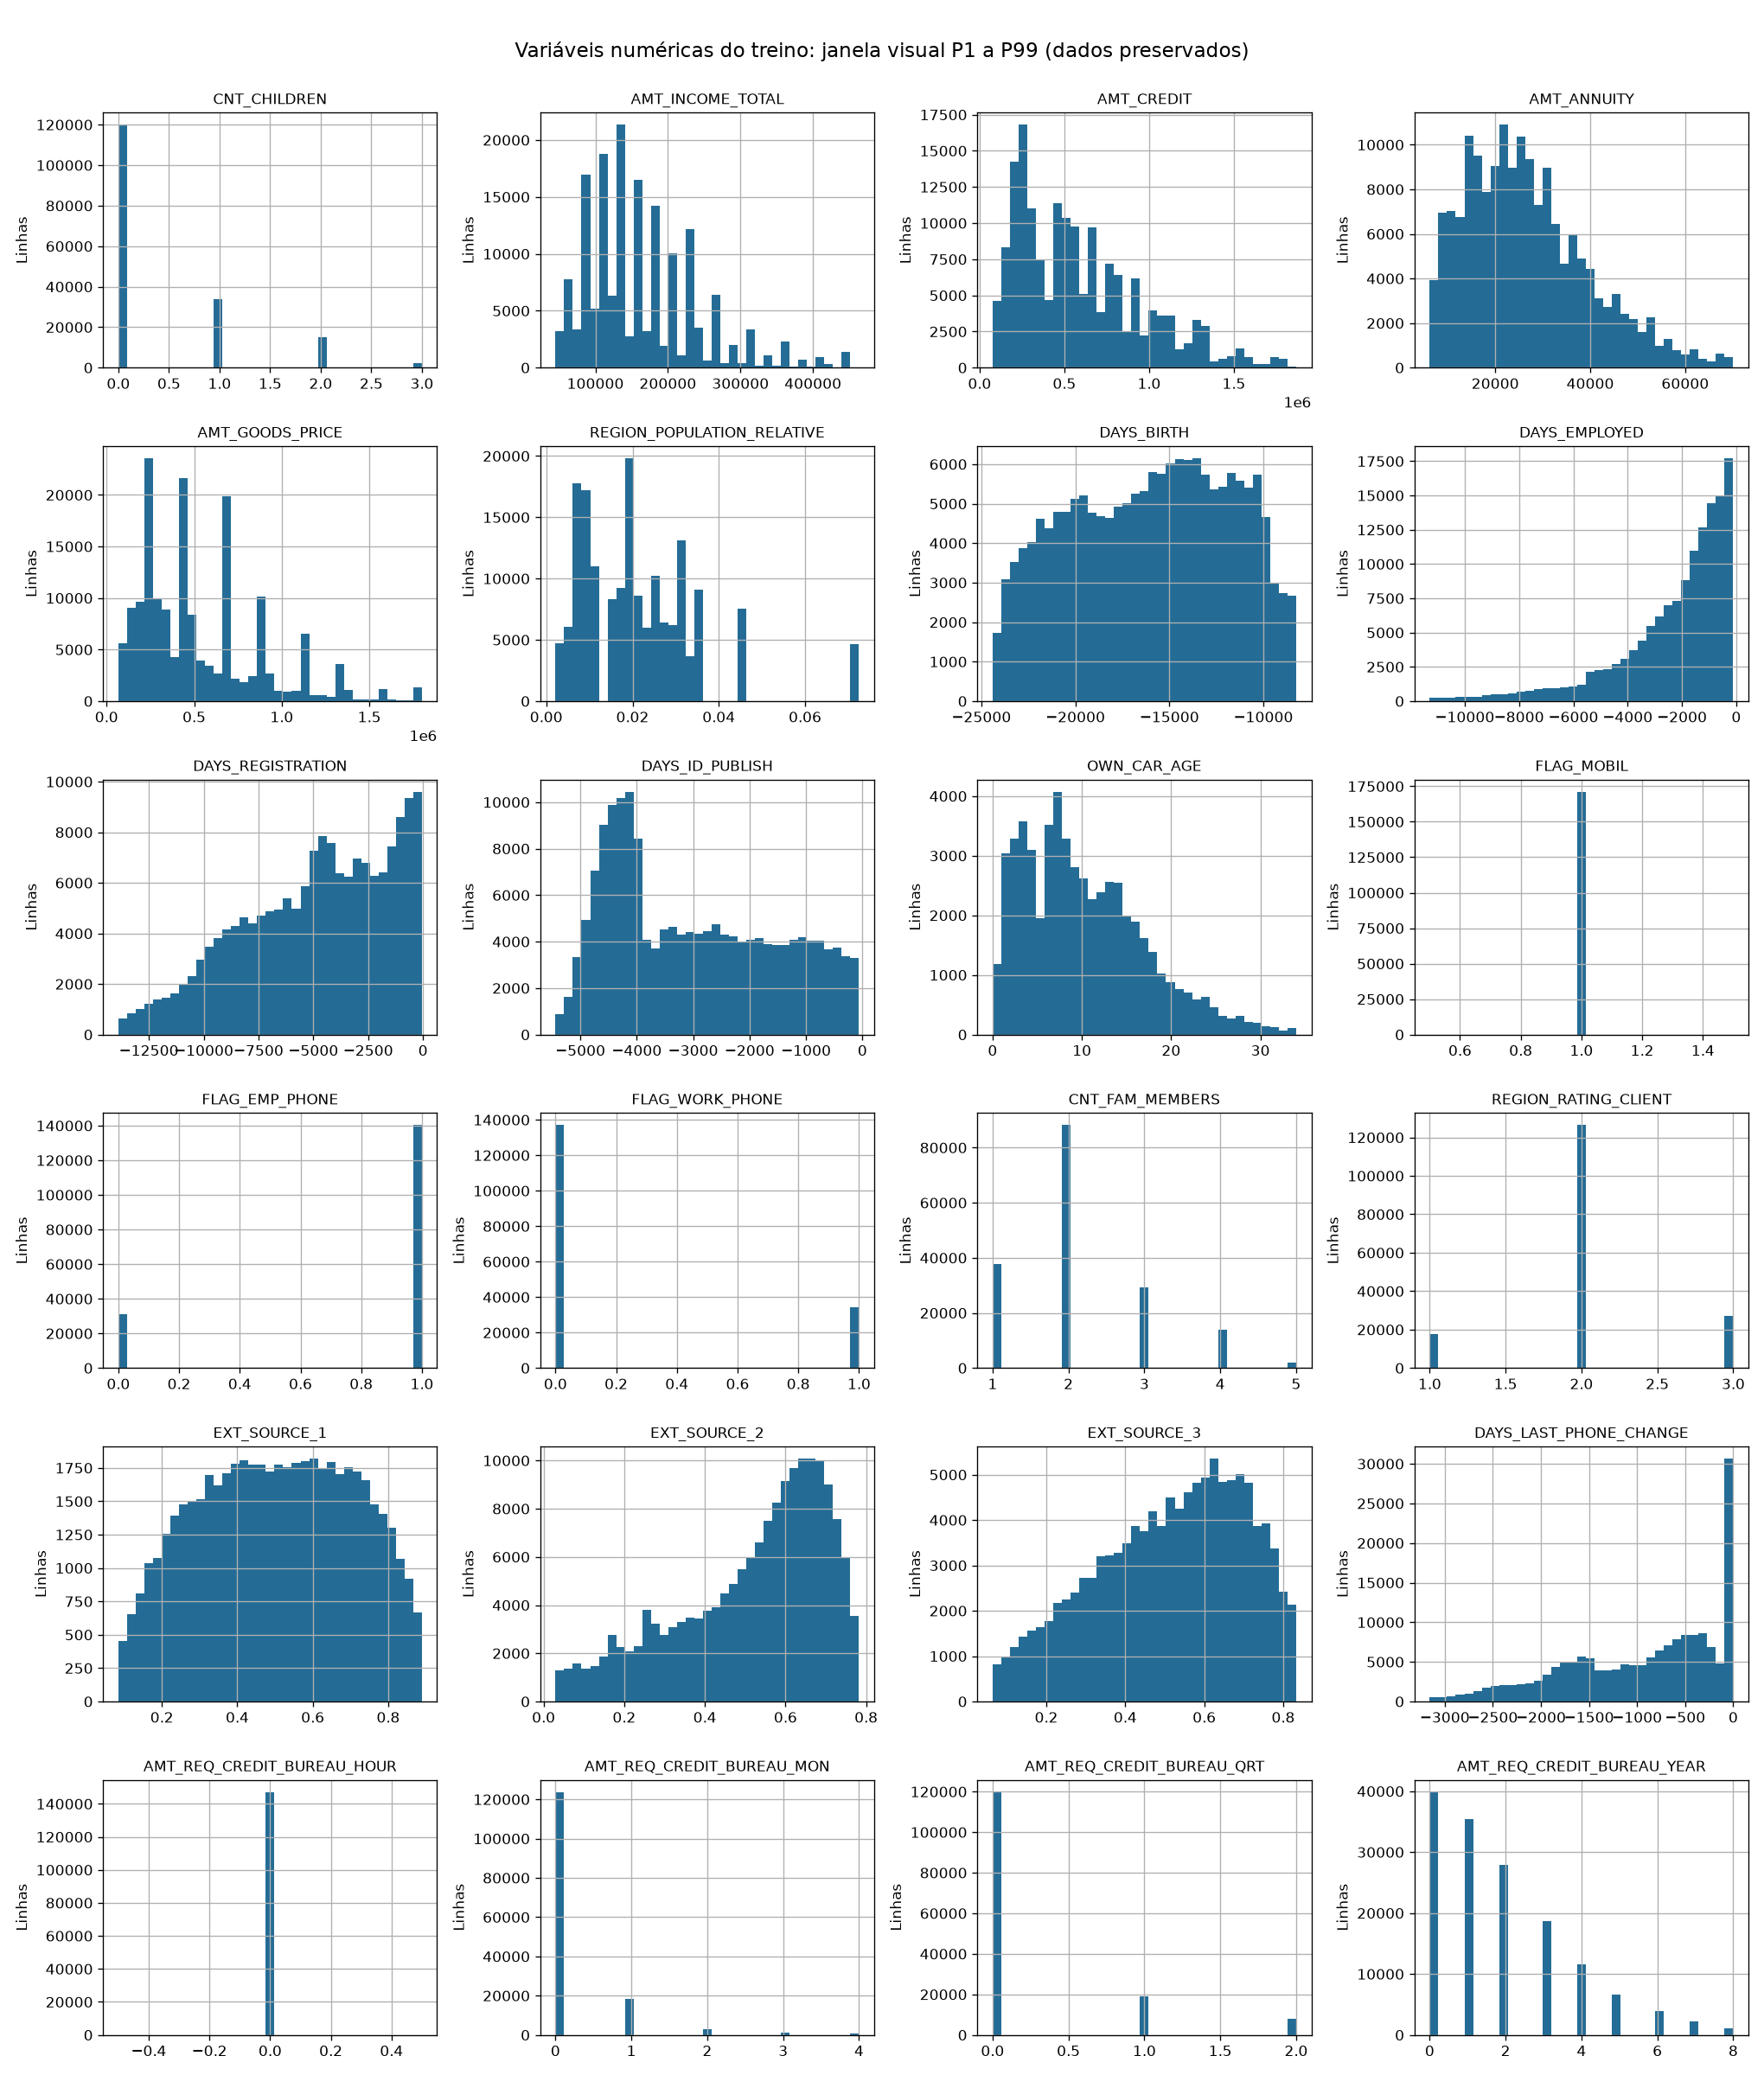

In [6]:
descritivas = []
outliers = []
for coluna in numericas:
    q1, q3 = train_limpo[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    for nome, dados in [("treino", train_limpo), ("teste", test_limpo)]:
        s = dados[coluna]
        desc = s.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_dict()
        desc.update({"base": nome, "coluna": coluna, "assimetria": s.skew(),
                     "zeros": int(s.eq(0).sum()), "ausentes": int(s.isna().sum())})
        descritivas.append(desc)
        mascara = s.lt(q1 - 1.5 * iqr) | s.gt(q3 + 1.5 * iqr)
        outliers.append({"base": nome, "coluna": coluna, "limite_inferior_treino": q1 - 1.5 * iqr,
            "limite_superior_treino": q3 + 1.5 * iqr, "iqr_zero": bool(iqr == 0),
            "sinalizados": int(mascara.sum()), "pct_observados": mascara.sum() / max(s.notna().sum(), 1) * 100})
descritivas = pd.DataFrame(descritivas)
descritivas.to_csv(REL / "estatisticas_numericas.csv", index=False)
pd.DataFrame(outliers).to_csv(REL / "outliers_iqr_diagnostico.csv", index=False)
fig, eixos = plt.subplots(6, 4, figsize=(17, 20))
for coluna, ax in zip(numericas, eixos.flat):
    valores = train_limpo[coluna].dropna()
    limite_inf, limite_sup = valores.quantile([0.01, 0.99])
    valores.loc[valores.between(limite_inf, limite_sup)].hist(bins=35, ax=ax, color="#246c96")
    ax.set_title(coluna, fontsize=10)
    ax.set_ylabel("Linhas")
fig.suptitle("Variáveis numéricas do treino: janela visual P1 a P99 (dados preservados)", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(FIG / "02_distribuicoes_numericas.png")
plt.close(fig)

## 6. Alvo, categorias e associações exploratórias
As relações com TARGET são calculadas apenas no treino. Não são causais.
As taxas de categorias pequenas são instáveis: incluímos n e intervalo de Wilson de 95%.
Correlação de Spearman mede associação monotônica; não mede toda relação possível.
Como a EDA usa o treino rotulado inteiro, a futura validação é exploratória.

TARGET: {0: 157381, 1: 13821} Taxa: 8.0729 %
                coluna  spearman_target  n_observado  magnitude
          EXT_SOURCE_3          -0.1659       116616     0.1659
          EXT_SOURCE_1          -0.1502        52274     0.1502
          EXT_SOURCE_2          -0.1493       170833     0.1493
            DAYS_BIRTH           0.0796       171202     0.0796
         DAYS_EMPLOYED           0.0786       140304     0.0786
  REGION_RATING_CLIENT           0.0589       171202     0.0589
       DAYS_ID_PUBLISH           0.0536       171202     0.0536
           OWN_CAR_AGE           0.0535        56384     0.0535
DAYS_LAST_PHONE_CHANGE           0.0534       171202     0.0534
        FLAG_EMP_PHONE           0.0456       171202     0.0456


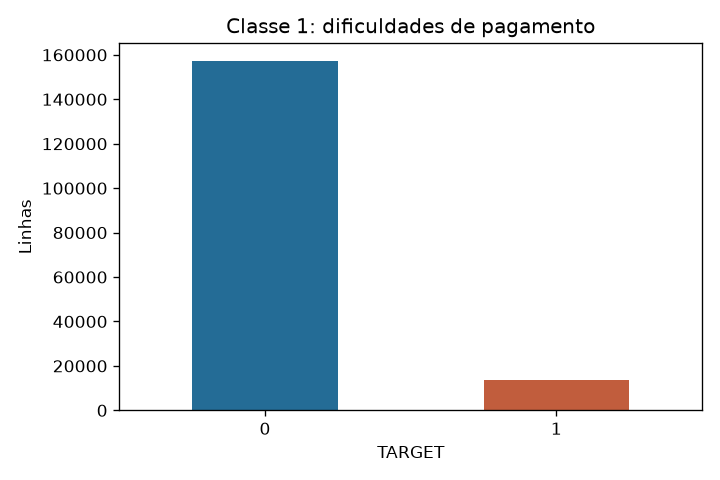

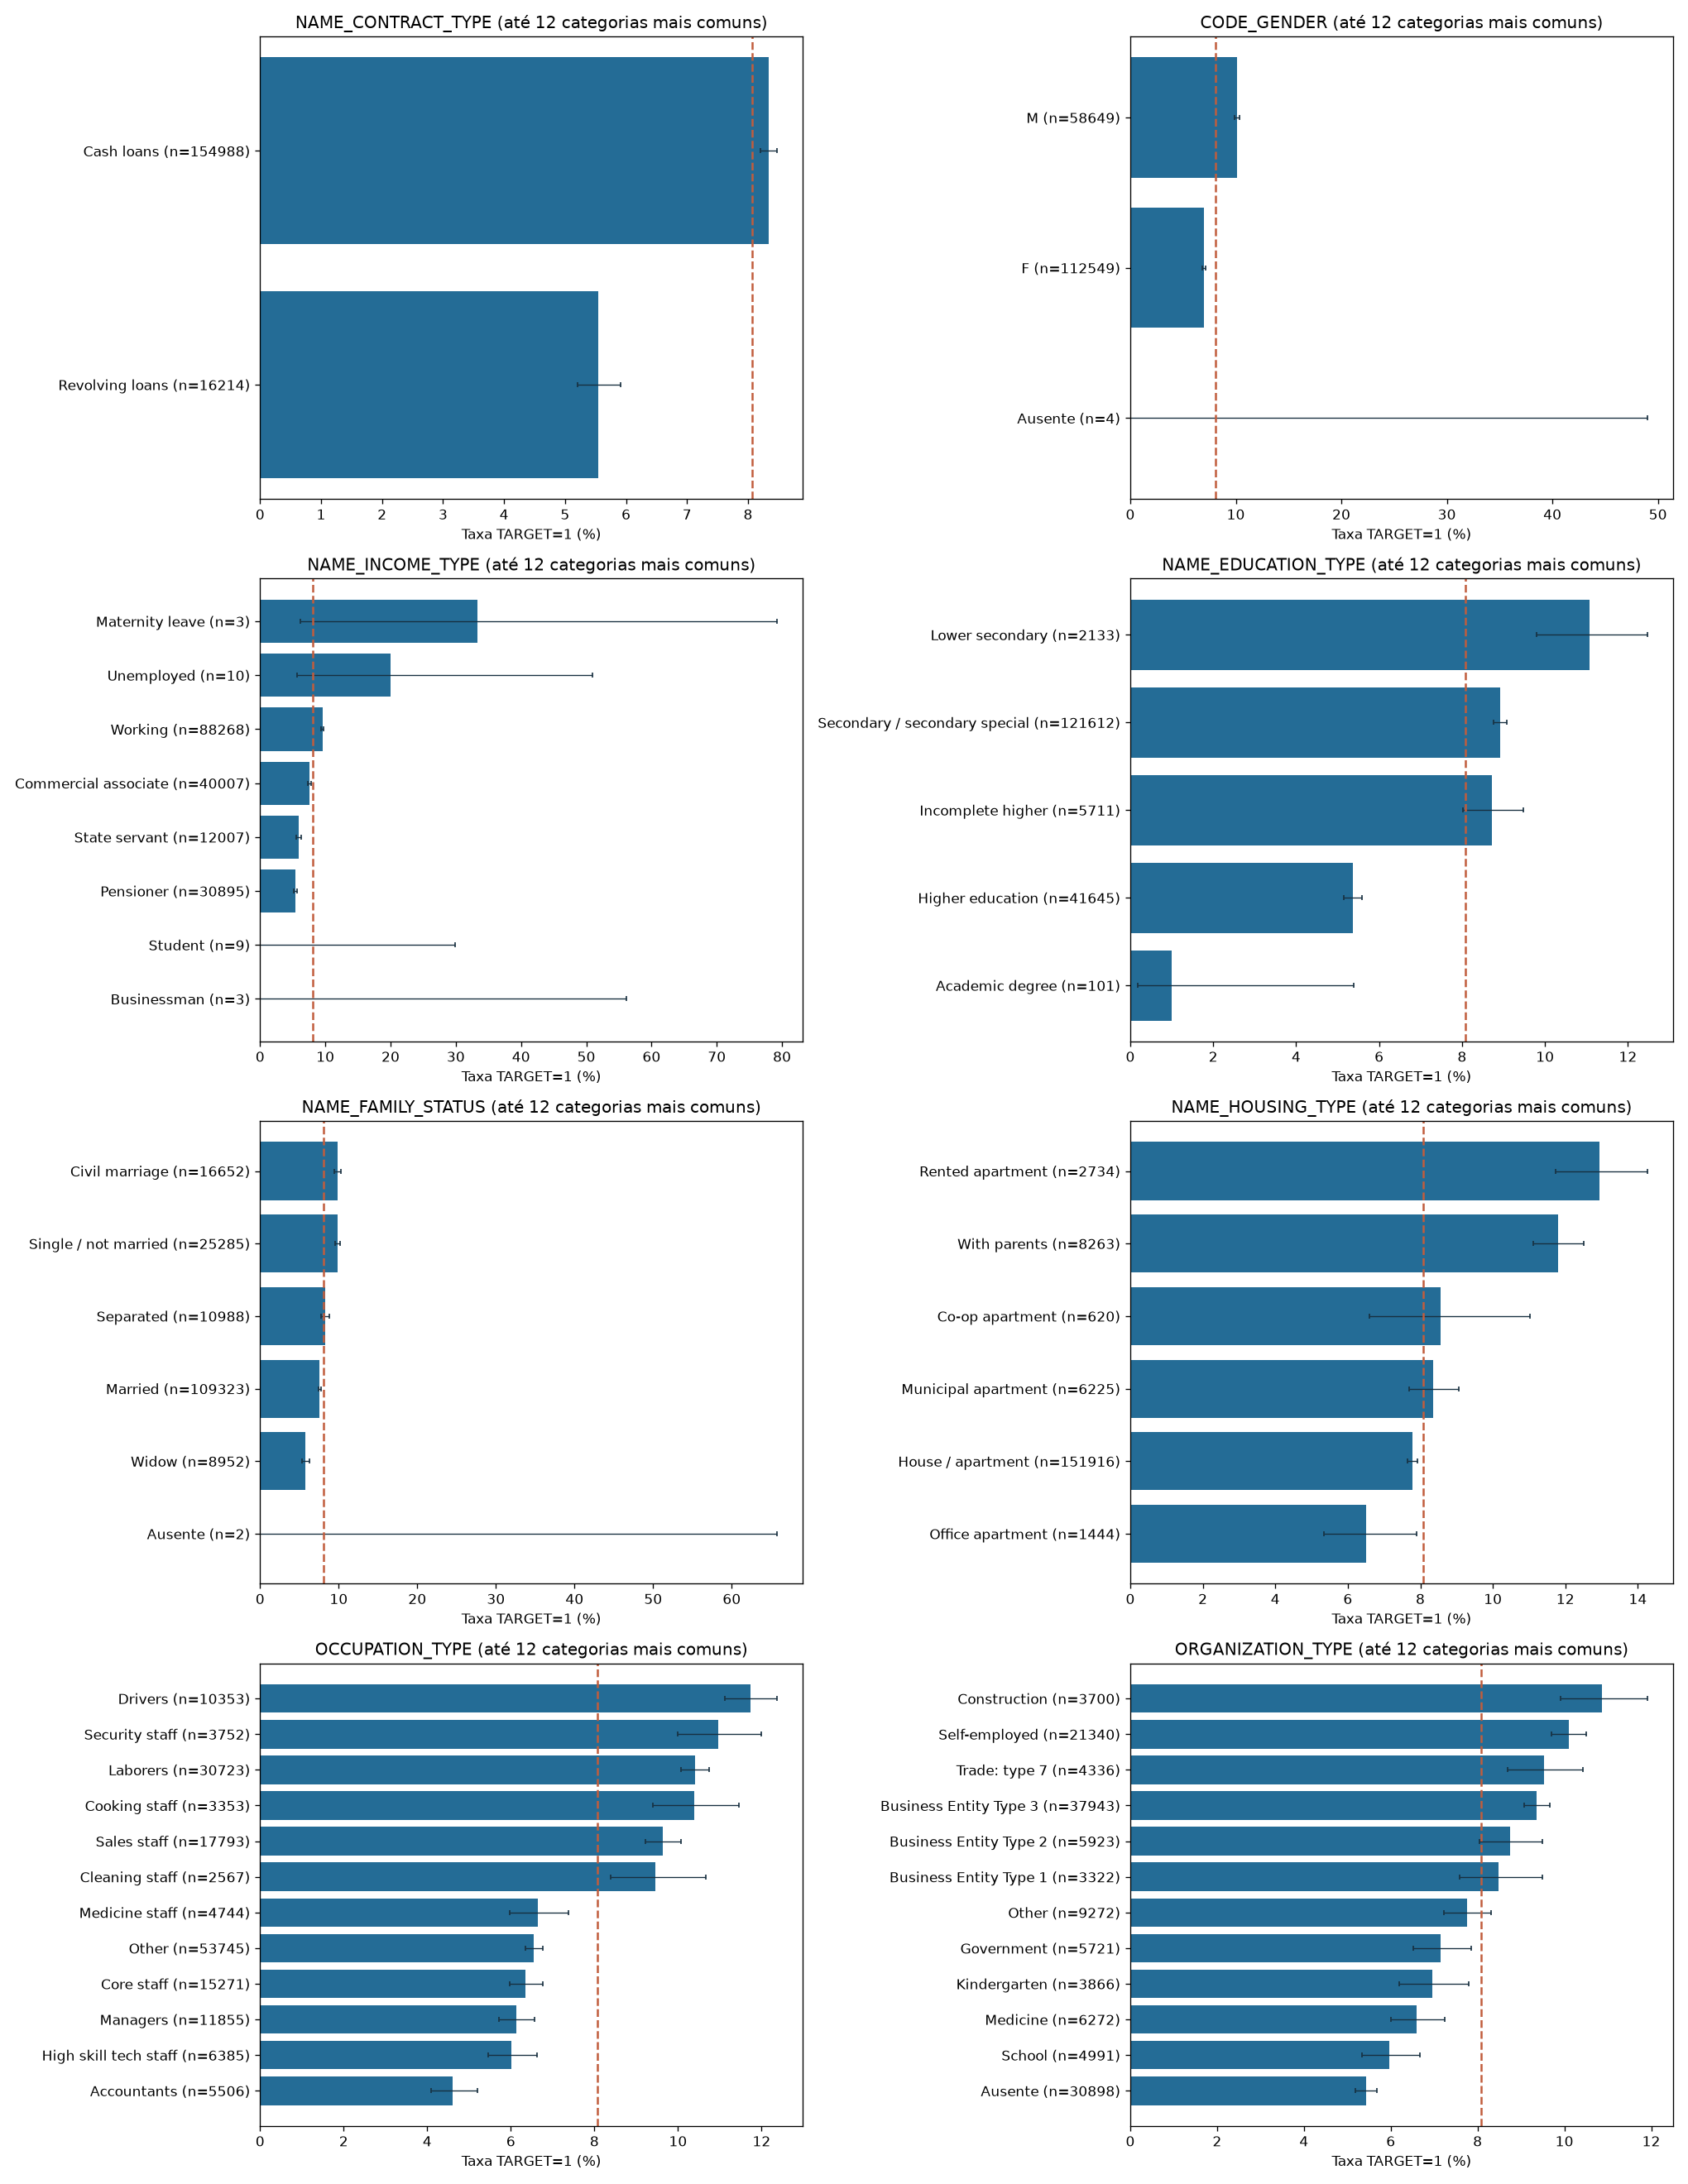

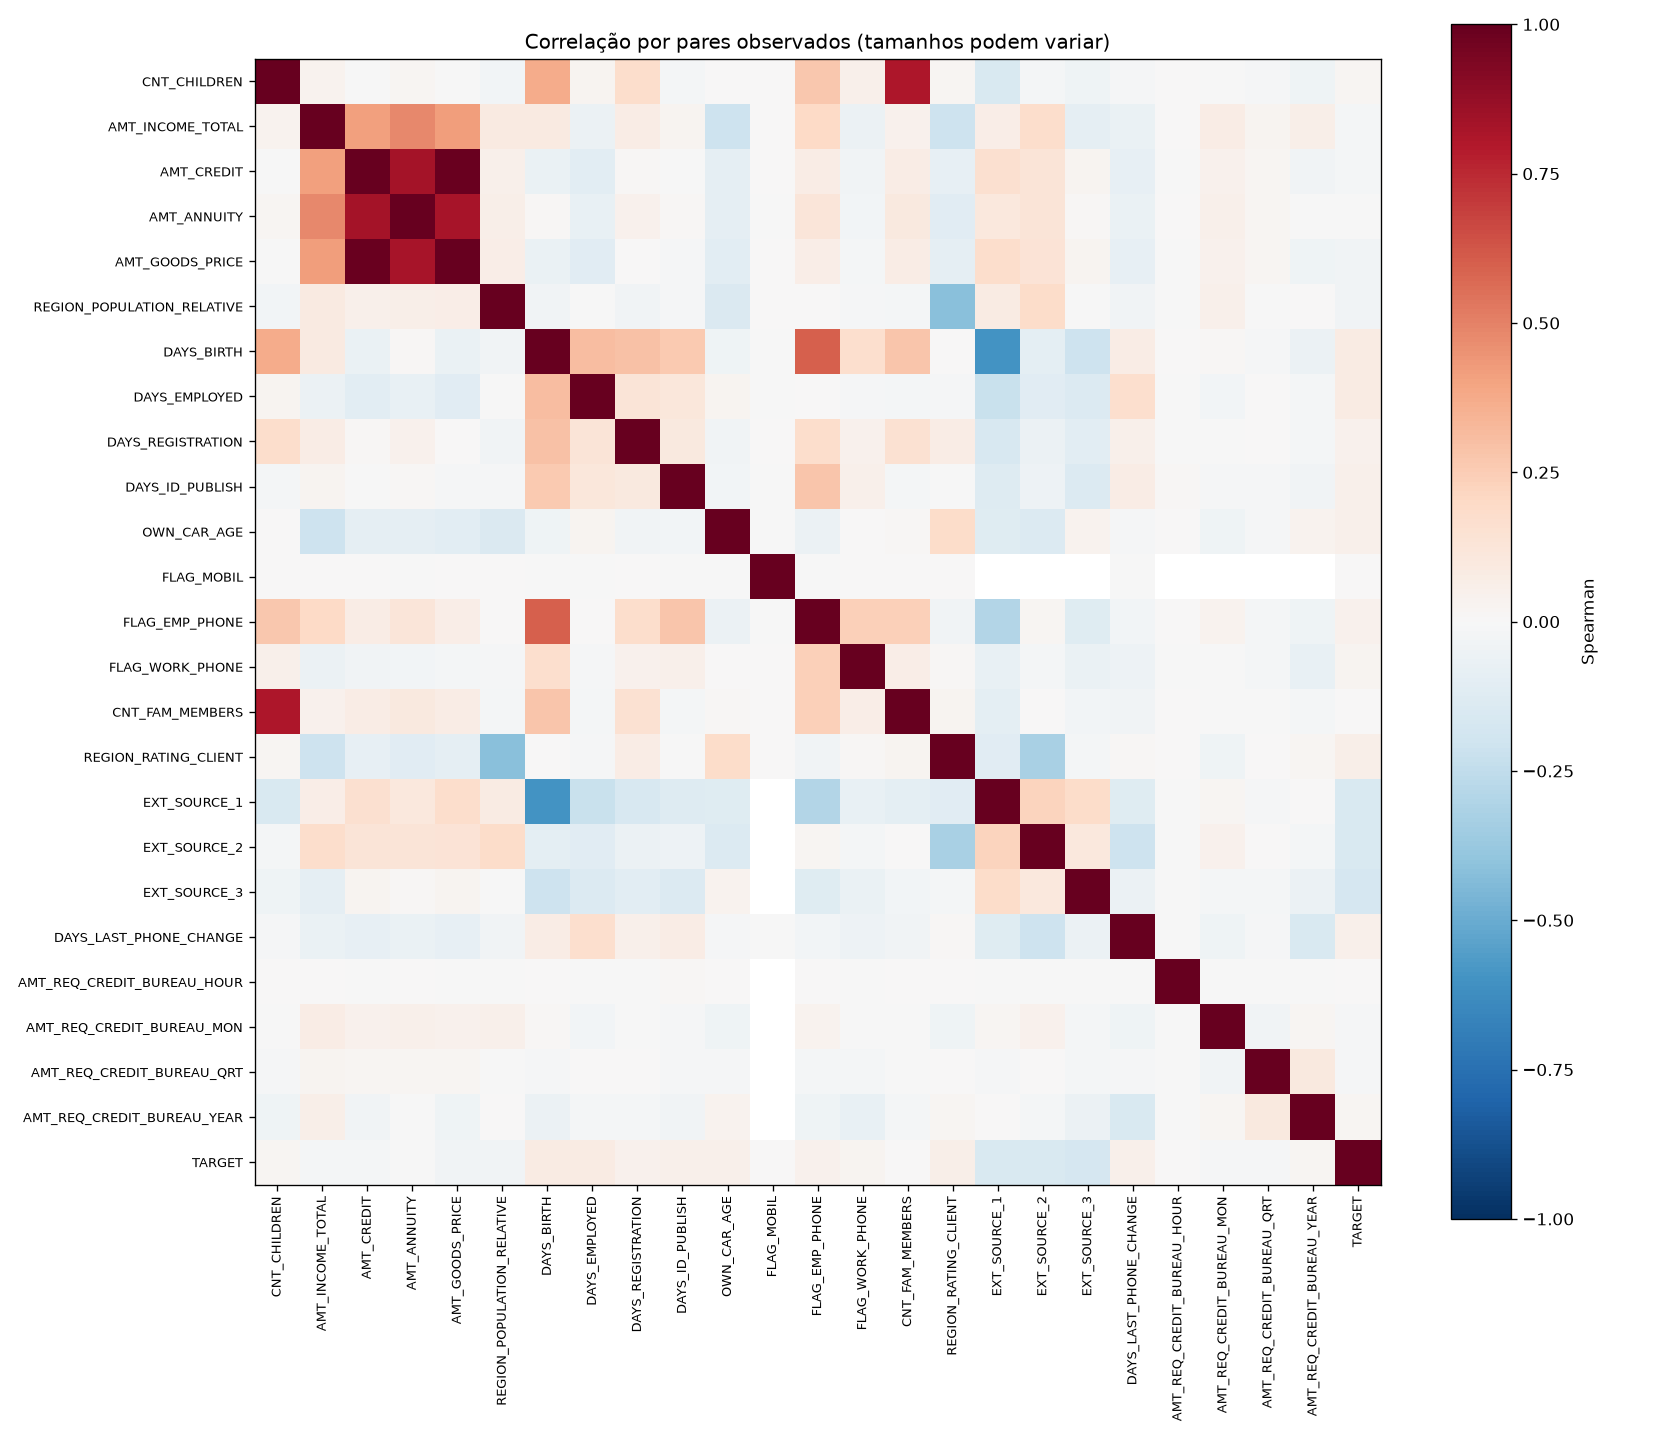

In [7]:
taxa_alvo = train["TARGET"].mean()
contagem_alvo = train["TARGET"].value_counts().sort_index()
print("TARGET:", contagem_alvo.to_dict(), "Taxa:", round(taxa_alvo * 100, 4), "%")
fig, ax = plt.subplots(figsize=(6, 4))
contagem_alvo.plot.bar(ax=ax, color=["#246c96", "#c15d3d"], rot=0)
ax.set(xlabel="TARGET", ylabel="Linhas", title="Classe 1: dificuldades de pagamento")
fig.tight_layout()
fig.savefig(FIG / "03_alvo.png")
plt.close(fig)
tabelas_categorias = []
for coluna in categoricas:
    grupos = train_limpo.groupby(train_limpo[coluna].fillna("Ausente"))["TARGET"].agg(["size", "sum", "mean"])
    grupos.columns = ["n", "eventos", "taxa"]
    z = 1.96
    centro = (grupos.taxa + z*z / (2*grupos.n)) / (1 + z*z/grupos.n)
    margem = z*np.sqrt(grupos.taxa*(1-grupos.taxa)/grupos.n + z*z/(4*grupos.n**2)) / (1+z*z/grupos.n)
    grupos["ic95_inferior"] = centro - margem
    grupos["ic95_superior"] = centro + margem
    grupos["categoria"] = grupos.index.astype(str)
    grupos["coluna"] = coluna
    tabelas_categorias.append(grupos.reset_index(drop=True))
taxas_categorias = pd.concat(tabelas_categorias, ignore_index=True)
taxas_categorias.to_csv(REL / "categorias_taxas_alvo.csv", index=False)
distribuicoes_categoricas = []
for nome, dados in [("treino", train_limpo), ("teste", test_limpo)]:
    for coluna in categoricas:
        frequencias = dados[coluna].fillna("Ausente").value_counts()
        for categoria, quantidade in frequencias.items():
            distribuicoes_categoricas.append({"base": nome, "coluna": coluna,
                "categoria": categoria, "n": int(quantidade), "pct": quantidade / len(dados) * 100})
pd.DataFrame(distribuicoes_categoricas).to_csv(REL / "frequencias_categoricas.csv", index=False)
fig, eixos = plt.subplots(4, 2, figsize=(17, 22))
for coluna, ax in zip(categoricas, eixos.flat):
    grupos = taxas_categorias.loc[taxas_categorias.coluna.eq(coluna)].nlargest(12, "n").sort_values("taxa")
    rotulos = grupos.categoria + " (n=" + grupos.n.astype(str) + ")"
    ax.barh(rotulos, grupos.taxa * 100, color="#246c96")
    ax.errorbar(grupos.taxa * 100, np.arange(len(grupos)),
        xerr=np.maximum(0, np.array([grupos.taxa-grupos.ic95_inferior,
                                    grupos.ic95_superior-grupos.taxa]) * 100),
        fmt="none", ecolor="#172f3f", capsize=2, linewidth=0.8)
    ax.axvline(taxa_alvo * 100, color="#c15d3d", linestyle="--")
    ax.set(title=coluna + " (até 12 categorias mais comuns)", xlabel="Taxa TARGET=1 (%)")
fig.tight_layout()
fig.savefig(FIG / "04_categorias_alvo.png")
plt.close(fig)
associacoes = []
ausencia_alvo = []
for coluna in numericas:
    validos = train_limpo[coluna].notna()
    rho = train_limpo.loc[validos, coluna].corr(train_limpo.loc[validos, "TARGET"], method="spearman")
    associacoes.append({"coluna": coluna, "spearman_target": rho,
                         "n_observado": int(validos.sum())})
for coluna in features:
    faltantes = train_limpo[coluna].isna()
    ausencia_alvo.append({"coluna": coluna, "n_ausentes": int(faltantes.sum()),
        "taxa_alvo_ausentes": train_limpo.loc[faltantes, "TARGET"].mean(),
        "taxa_alvo_presentes": train_limpo.loc[~faltantes, "TARGET"].mean()})
associacoes = pd.DataFrame(associacoes)
associacoes["magnitude"] = associacoes.spearman_target.abs()
associacoes = associacoes.sort_values("magnitude", ascending=False)
associacoes.to_csv(REL / "associacoes_numericas_alvo.csv", index=False)
pd.DataFrame(ausencia_alvo).to_csv(REL / "ausencia_e_alvo.csv", index=False)
taxas_numericas = []
for coluna in numericas:
    if train_limpo[coluna].nunique() < 2:
        continue
    if train_limpo[coluna].nunique() <= 10:
        faixas_num = train_limpo[coluna].astype("string")
    else:
        faixas_num = pd.qcut(train_limpo[coluna], q=10, duplicates="drop")
    faixas_num = faixas_num.astype("string").fillna("Ausente")
    grupos_num = train_limpo.groupby(faixas_num)["TARGET"].agg(["size", "sum", "mean"])
    grupos_num.columns = ["n", "eventos", "taxa"]
    grupos_num["faixa"] = grupos_num.index.astype(str)
    grupos_num["coluna"] = coluna
    taxas_numericas.append(grupos_num.reset_index(drop=True))
pd.concat(taxas_numericas, ignore_index=True).to_csv(REL / "faixas_numericas_taxas_alvo.csv", index=False)
print(associacoes.head(10).round(4).to_string(index=False))
correlacoes = train_limpo[numericas + ["TARGET"]].corr(method="spearman")
correlacoes.to_csv(REL / "correlacoes_spearman.csv")
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(correlacoes, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(correlacoes)), correlacoes.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(correlacoes)), correlacoes.columns, fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman")
ax.set_title("Correlação por pares observados (tamanhos podem variar)")
fig.tight_layout()
fig.savefig(FIG / "05_correlacoes.png")
plt.close(fig)

## 7. Treino versus teste
Comparamos ausências, categorias novas, medianas e estatística KS.
KS é uma distância entre distribuições numéricas; o p-valor é sensível ao tamanho amostral.
TVD compara proporções das categorias e varia entre 0 e 1.
Não comparamos TARGET no teste porque seus rótulos não foram fornecidos.

                coluna  diferenca_ausencia_pp     tipo  tvd categorias_exclusivas_teste  linhas_categorias_novas_teste     ks   p_ks  mediana_treino  mediana_teste
          EXT_SOURCE_3                 0.1323 numerica  NaN                         NaN                            NaN 0.0293 0.0000          0.5371         0.5209
          EXT_SOURCE_2                -0.0042 numerica  NaN                         NaN                            NaN 0.0226 0.0000          0.5663         0.5562
          EXT_SOURCE_1                 0.3091 numerica  NaN                         NaN                            NaN 0.0220 0.0000          0.5059         0.4929
         DAYS_EMPLOYED                -0.8688 numerica  NaN                         NaN                            NaN 0.0176 0.0000      -1650.0000     -1589.0000
            DAYS_BIRTH                 0.0000 numerica  NaN                         NaN                            NaN 0.0138 0.0000     -15778.0000    -15586.5000
           OWN_C

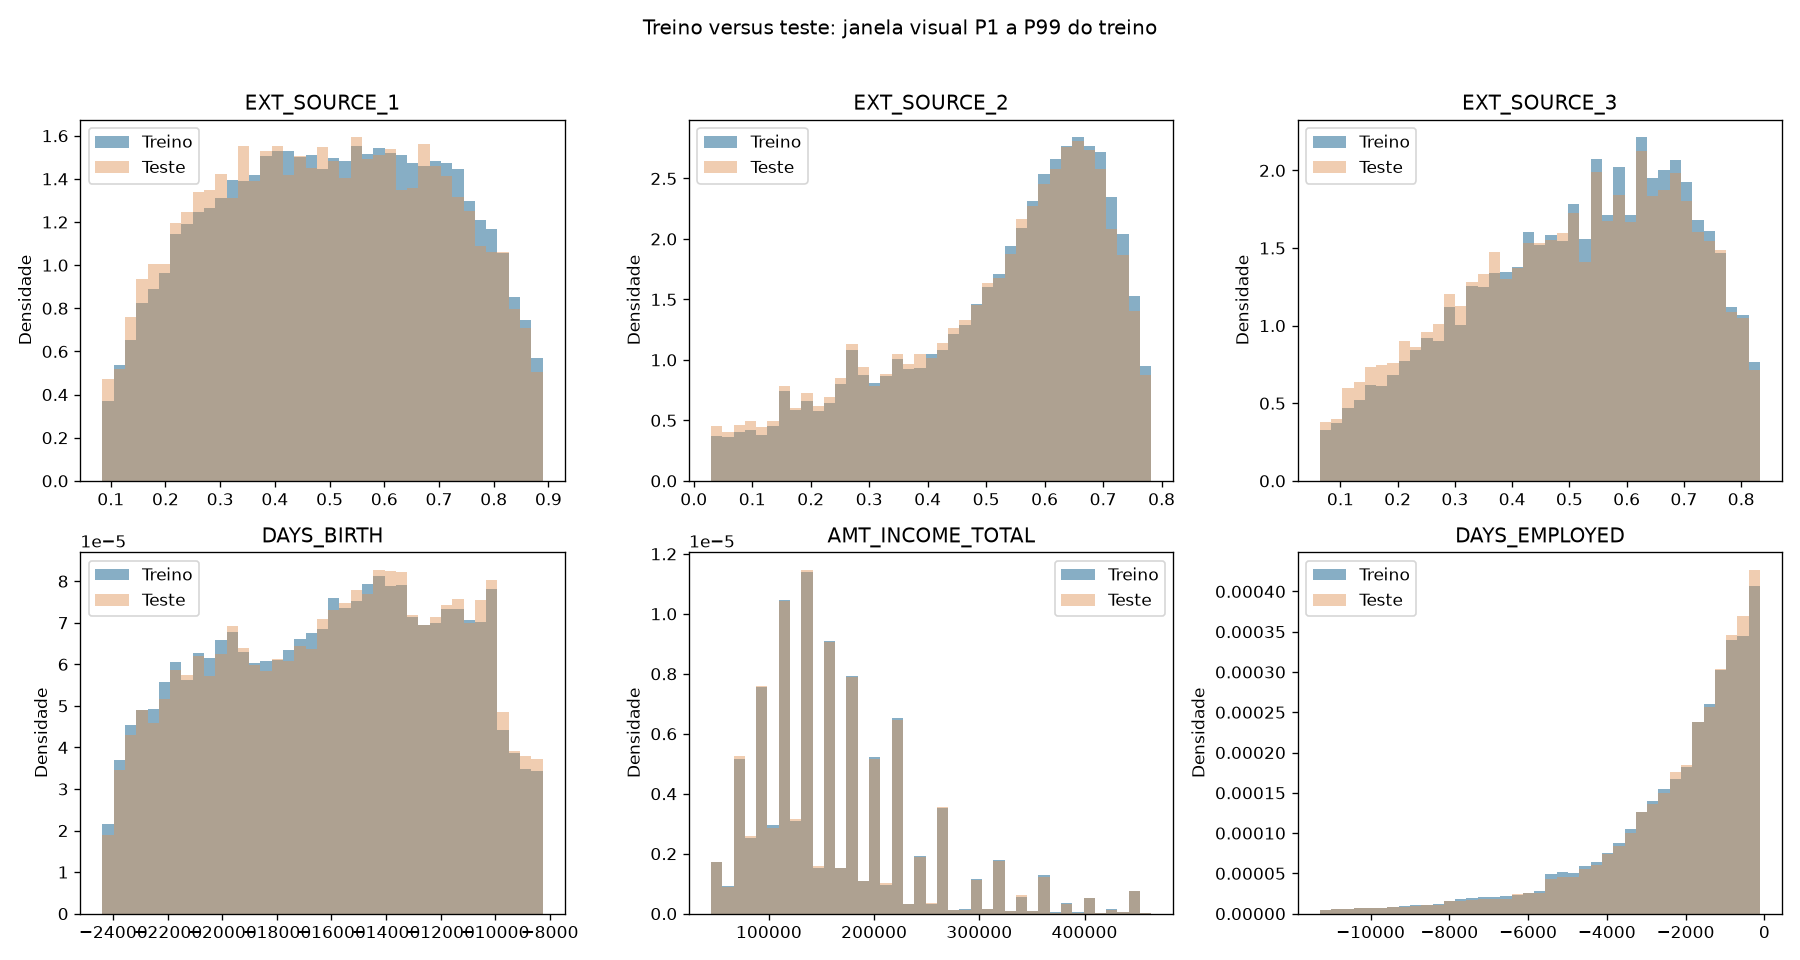

In [8]:
comparacoes = []
for coluna in features:
    a = train_limpo[coluna]
    b = test_limpo[coluna]
    linha = {"coluna": coluna, "diferenca_ausencia_pp": (b.isna().mean() - a.isna().mean()) * 100}
    if coluna in numericas:
        ks = ks_2samp(a.dropna(), b.dropna(), method="asymp")
        linha.update({"tipo": "numerica", "ks": float(ks.statistic), "p_ks": float(ks.pvalue),
            "mediana_treino": a.median(), "mediana_teste": b.median()})
    else:
        pa = a.fillna("Ausente").value_counts(normalize=True)
        pb = b.fillna("Ausente").value_counts(normalize=True)
        categorias_unidas = pa.index.union(pb.index)
        tvd = (pa.reindex(categorias_unidas, fill_value=0) - pb.reindex(categorias_unidas, fill_value=0)).abs().sum()/2
        novas = sorted(set(b.dropna().unique()) - set(a.dropna().unique()))
        linha.update({"tipo": "categorica", "tvd": tvd,
            "categorias_exclusivas_teste": json.dumps(novas, ensure_ascii=False),
            "linhas_categorias_novas_teste": int(b.isin(novas).sum())})
    comparacoes.append(linha)
comparacoes = pd.DataFrame(comparacoes)
comparacoes.to_csv(REL / "comparacao_treino_teste.csv", index=False)
print(comparacoes.loc[comparacoes.tipo.eq("numerica")].nlargest(8, "ks").round(4).to_string(index=False))
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
colunas_grafico = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH", "AMT_INCOME_TOTAL", "DAYS_EMPLOYED"]
for coluna, ax in zip(colunas_grafico, eixos.flat):
    lo, hi = train_limpo[coluna].quantile([0.01, 0.99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(train_limpo[coluna].dropna(), bins=bins, density=True, alpha=0.55, label="Treino", color="#246c96")
    ax.hist(test_limpo[coluna].dropna(), bins=bins, density=True, alpha=0.45, label="Teste", color="#df9252")
    ax.set(title=coluna, ylabel="Densidade")
    ax.legend()
fig.suptitle("Treino versus teste: janela visual P1 a P99 do treino")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG / "06_treino_teste.png")
plt.close(fig)

## 8. Idade e dimensões financeiras
A idade em anos serve apenas à leitura dos gráficos; preservamos DAYS_BIRTH na base.
Os valores monetários não têm moeda ou unidade confirmada no dicionário.
Extremos não foram removidos. Apenas o gráfico usa log10 para enxergar a renda.

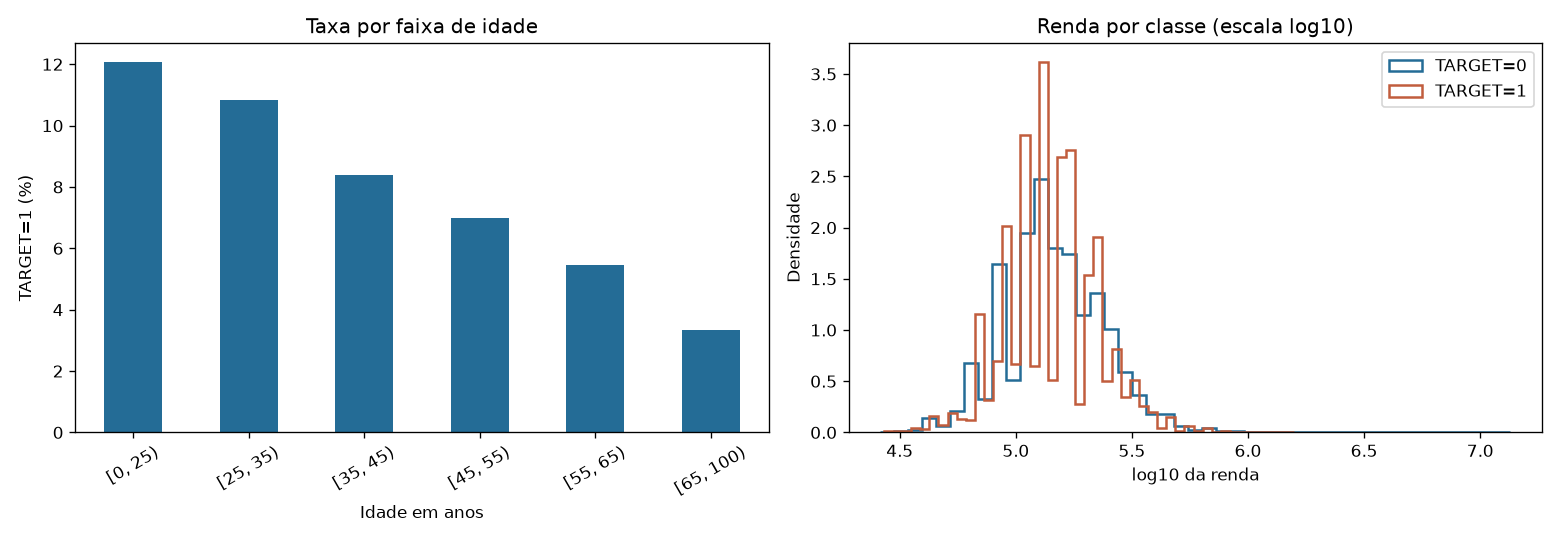

In [9]:
faixas = pd.cut(-train_limpo["DAYS_BIRTH"]/365.25,
               bins=[0, 25, 35, 45, 55, 65, 100], right=False)
faixas_alvo = train_limpo.groupby(faixas, observed=True)["TARGET"].agg(["size", "mean"])
faixas_alvo.index.name = "idade_anos"
faixas_alvo.to_csv(REL / "idade_taxas_alvo.csv")
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
faixas_alvo["mean"].mul(100).plot.bar(ax=eixos[0], color="#246c96", rot=30)
eixos[0].set(title="Taxa por faixa de idade", ylabel="TARGET=1 (%)", xlabel="Idade em anos")
for alvo, cor in [(0, "#246c96"), (1, "#c15d3d")]:
    renda = train_limpo.loc[train_limpo.TARGET.eq(alvo), "AMT_INCOME_TOTAL"].dropna()
    eixos[1].hist(np.log10(renda), bins=45, density=True, histtype="step", linewidth=1.5, label=f"TARGET={alvo}", color=cor)
eixos[1].set(title="Renda por classe (escala log10)", xlabel="log10 da renda", ylabel="Densidade")
eixos[1].legend()
fig.tight_layout()
fig.savefig(FIG / "07_idade_renda.png")
plt.close(fig)

## 9. Dados numéricos preparados para o ensemble
Divisão estratificada 70/30 com random_state=42 antes de ajustar medianas/categorias.
A limpeza determinística não usa TARGET. A imputação usa somente o subtreino.
Mantemos indicador de ausência para cada variável numérica, preenchemos textos com
Ausente e aplicamos one-hot encoding. Categorias novas ficam com zeros nas dummies.
SK_ID_CURR e TARGET são mantidos nos CSVs para identificação; devem ser retirados de X.
Não fazemos oversampling, corte por IQR ou padronização para árvores nesta etapa.

In [10]:
idx_treino, idx_validacao = train_test_split(
    np.arange(len(train_limpo)), test_size=0.30, random_state=42, stratify=train_limpo["TARGET"]
)
X_train = train_limpo.iloc[idx_treino][features].copy()
X_valid = train_limpo.iloc[idx_validacao][features].copy()
X_test = test_limpo[features].copy()
categorias_nao_vistas = []
for coluna in categoricas:
    conhecidas = set(X_train[coluna].dropna())
    for nome, dados in [("validacao", X_valid), ("teste", X_test)]:
        novas = dados[coluna].notna() & ~dados[coluna].isin(conhecidas)
        categorias_nao_vistas.append({"base": nome, "coluna": coluna,
            "linhas_novas": int(novas.sum()), "categorias": json.dumps(sorted(dados.loc[novas, coluna].unique().tolist()), ensure_ascii=False)})
pd.DataFrame(categorias_nao_vistas).to_csv(REL / "categorias_nao_vistas_subtreino.csv", index=False)
for dados in [X_train, X_valid, X_test]:
    for coluna in numericas:
        dados[coluna + "_AUSENTE"] = dados[coluna].isna().astype("int8")
    dados[categoricas] = dados[categoricas].fillna("Ausente")
medianas = X_train[numericas].median().fillna(0)
medianas.to_csv(MODELO / "medianas_subtreino.csv", header=["mediana"])
for dados in [X_train, X_valid, X_test]:
    dados[numericas] = dados[numericas].fillna(medianas)
X_train = pd.get_dummies(X_train, columns=categoricas, dtype="int8")
X_valid = pd.get_dummies(X_valid, columns=categoricas, dtype="int8").reindex(columns=X_train.columns, fill_value=0)
X_test = pd.get_dummies(X_test, columns=categoricas, dtype="int8").reindex(columns=X_train.columns, fill_value=0)
constantes = X_train.columns[X_train.nunique().le(1)].tolist()
pd.DataFrame({"coluna_removida_constante_subtreino": constantes}).to_csv(MODELO / "colunas_constantes.csv", index=False)
X_train = X_train.drop(columns=constantes)
X_valid = X_valid.drop(columns=constantes)
X_test = X_test.drop(columns=constantes)
colunas_modelo = X_train.columns.tolist()
(MODELO / "colunas_modelo.json").write_text(json.dumps(colunas_modelo, indent=2), encoding="utf-8")
for nome, X_dados, origem in [("treino", X_train, train_limpo.iloc[idx_treino]),
                              ("validacao", X_valid, train_limpo.iloc[idx_validacao]),
                              ("teste", X_test, test_limpo)]:
    assert X_dados.columns.tolist() == colunas_modelo
    assert np.isfinite(X_dados.to_numpy(dtype=float)).all()
    saida = X_dados.copy()
    saida.insert(0, "SK_ID_CURR", origem["SK_ID_CURR"].to_numpy())
    if nome != "teste":
        saida["TARGET"] = origem["TARGET"].to_numpy()
    saida.to_csv(MODELO / f"{nome}.csv", index=False)
    print(nome, saida.shape)
pd.DataFrame({"SK_ID_CURR": train_limpo.SK_ID_CURR,
    "particao": np.where(train_limpo.index.isin(idx_treino), "treino", "validacao")}).to_csv(MODELO / "particoes.csv", index=False)

treino (119841, 142)
validacao (51361, 142)
teste (61500, 141)


## 10. Verificações após tratamento
Conferimos preservação de linhas, IDs, TARGET, alinhamento e ausência de infinitos.
Os dados limpos preservam ausências; as matrizes de modelagem estão preenchidas.

In [11]:
assert train_limpo.shape == train.shape and test_limpo.shape == test.shape
assert train_limpo["SK_ID_CURR"].equals(train["SK_ID_CURR"])
assert test_limpo["SK_ID_CURR"].equals(test["SK_ID_CURR"])
assert train_limpo["TARGET"].equals(train["TARGET"])
assert len(X_train) + len(X_valid) == len(train)
assert set(train_limpo.iloc[idx_treino].SK_ID_CURR).isdisjoint(train_limpo.iloc[idx_validacao].SK_ID_CURR)
assert set(colunas_modelo).isdisjoint({"SK_ID_CURR", "TARGET"})
assert (train_limpo.DAYS_EMPLOYED.dropna() <= 0).all()
assert (train_limpo.OWN_CAR_AGE.dropna() < 60).all()
for item in manifesto:
    assert hashlib.sha256((BASE / "input" / item["arquivo"]).read_bytes()).hexdigest() == item["sha256"]
verificacao = {"linhas_e_ids_preservados": True, "target_preservado": True,
    "originais_sha256_inalterados": True, "particoes_sem_ids_sobrepostos": True,
    "modelo_sem_na_ou_inf": True, "mesmas_colunas_modelagem": True,
    "n_features_modelagem": len(colunas_modelo), "constantes_removidas": constantes,
    "treino_modelagem": len(X_train), "validacao_modelagem": len(X_valid), "teste": len(X_test),
    "semente": 42, "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit_learn": sklearn.__version__, "scipy": __import__("scipy").__version__, "matplotlib": matplotlib.__version__}
(REL / "verificacoes.json").write_text(json.dumps(verificacao, indent=2, ensure_ascii=False), encoding="utf-8")
print("Verificações concluídas. Originais preservados.")

Verificações concluídas. Originais preservados.


## 11. Relatório interpretativo
Resultados calculados são escritos em Markdown e HTML, acompanhados das tabelas CSV.
Associações são descritivas e não justificam decisões de concessão de crédito.

In [12]:
maiores_ausencias = ausencias_limpas.sort_values("treino_pct", ascending=False).head(10)
maiores_ks = comparacoes.loc[comparacoes.tipo.eq("numerica")].nlargest(5, "ks")
maiores_tvd = comparacoes.loc[comparacoes.tipo.eq("categorica")].nlargest(5, "tvd")
alteracoes = log_limpeza.loc[log_limpeza.celulas_alteradas.gt(0)].copy()
texto = ["# Análise exploratória e tratamento — Home Credit GCI", "",
    "Data da análise: 19/10/2026. Escopo: todas as linhas e todas as 32 variáveis dos CSVs fornecidos.", "",
    "## Dados e integridade", "",
    f"Treino: **{len(train):,} linhas × {train.shape[1]} colunas**. Teste: **{len(test):,} linhas × {test.shape[1]} colunas**. "
    f"São {len(numericas)} variáveis numéricas e {len(categoricas)} categóricas, além de ID e alvo no treino.", "",
    "O alvo descreve dificuldades de pagamento conforme a definição do curso. Não há datas de coleta ou confirmação da moeda dos valores monetários. "
    "Os IDs são identificadores reindexados e não representam tempo de observação.", "",
    "IDs únicos, sem interseção entre bases; estrutura do teste compatível e ordem dos IDs igual à do modelo de submissão. "
    "Detalhes e SHA-256 dos arquivos estão em integridade.csv e manifesto_originais.csv.", "",
    integridade.to_markdown(index=False), "",
    "Perfis repetidos sem ID/alvo são apenas sinalizados. Sem outra chave de cliente, não há evidência para excluí-los ou dizer que são a mesma pessoa.", "",
    "## Distribuição do alvo", "",
    f"TARGET=1: **{int(contagem_alvo.loc[1]):,} casos ({taxa_alvo:.2%})**. TARGET=0: **{int(contagem_alvo.loc[0]):,} casos**. "
    f"Prever sempre zero daria acurácia de {1-taxa_alvo:.2%}, mas não identificaria nenhum evento positivo. A avaliação da competição é ROC-AUC.", "",
    "![Alvo](graficos/03_alvo.png)", "",
    "## Ausências", "", maiores_ausencias.round(3).to_markdown(), "",
    "As porcentagens acima são após a limpeza. O diagnóstico original está em ausencias_originais.csv. "
    "OWN_CAR_AGE pode estar ausente porque não há carro ou porque a idade é desconhecida; estes arquivos não permitem distinguir as situações. "
    "O mesmo cuidado vale para scores e consultas ausentes: não se pode concluir que ausência significa score zero ou nenhuma consulta. "
    "Indicadores de ausência são mantidos nas matrizes de modelagem; nenhuma variável foi excluída apenas por ter muitas lacunas.", "",
    "![Ausências originais](graficos/01_ausencias.png)", "",
    "## Limpeza realizada", "", alteracoes.to_markdown(index=False), "",
    "Foram aparados espaços e convertidos XNA, XAP, Unknown e textos vazios em ausência. "
    "As categorias são marcadores tratados como desconhecidos por hipótese explícita; preservamos o log para permitir outra decisão. "
    "Dias positivos foram marcados como ausentes, incluindo a sentinela 365243 em DAYS_EMPLOYED. "
    "Dias negativos e zero foram preservados, pois representam tempo anterior ou o dia do pedido. "
    "Idade de carro >=60 segue a hipótese proposta no tutorial e deve ser comparada com uma versão que preserve esses valores. "
    "Valores numéricos fora dos domínios foram tratados conforme auditoria_valores.csv. "
    "O log conta células alteradas por regra, não clientes únicos. Nenhuma linha ou TARGET foi excluído ou alterado.", "",
    "## Distribuições, extremos e consistência", "",
    "estatisticas_numericas.csv contém mínimo, máximo, média, desvio, mediana, quantis, zeros e assimetria de cada variável nas duas bases. "
    "As distribuições de renda/crédito podem ter cauda longa. Valores extremos são sinalizados por limites de IQR do treino e foram preservados. "
    "Em variáveis discretas ou IQR zero, esse detector pode gerar muitos alertas sem indicar erros. "
    "A auditoria também verifica família versus filhos e tempo empregado versus idade; inconsistência sem solução comprovada não é corrigida por inferência.", "",
    "![Distribuições](graficos/02_distribuicoes_numericas.png)", "",
    "O histograma acima mostra a janela P1–P99 de cada variável; todos os extremos permanecem nas tabelas e nas bases. "
    "O recorte é visual e não uma operação de limpeza.", "",
    f"Na renda, a mediana do treino é {train_limpo.AMT_INCOME_TOTAL.median():,.0f} e a do teste é {test_limpo.AMT_INCOME_TOTAL.median():,.0f}. "
    f"Entretanto, o máximo é {train_limpo.AMT_INCOME_TOTAL.max():,.0f} no treino e {test_limpo.AMT_INCOME_TOTAL.max():,.0f} no teste. "
    "Esse extremo do teste fica fora da faixa vista no treino e aumenta a assimetria. Sem confirmação da fonte, não há base para substituir seu valor. "
    "Vale comparar, dentro de validação adequada, uma transformação logarítmica ou um limite aprendido apenas no subtreino, preservando a versão original.", "",
    "## Relações com dificuldades de pagamento", "",
    associacoes.head(10).round(4).to_markdown(index=False), "",
    "Os três scores EXT_SOURCE aparecem no topo das associações individuais. A direção negativa indica que scores menores acompanham maior frequência de TARGET=1 entre os valores observados. "
    "A correlação positiva de DAYS_BIRTH requer atenção ao sinal: dias menos negativos correspondem a clientes mais jovens, não mais velhos. "
    "A relação com DAYS_EMPLOYED também usa dias negativos e exclui as sentinelas tratadas. Comparar essas variáveis demanda considerar suas ausências e possíveis fatores de confusão.", "",
    "As correlações de Spearman acima usam apenas pares observados. O número de observações muda entre colunas, principalmente nas fontes externas. "
    "As maiores associações são hipóteses para modelagem, não ranking causal nem importância de um modelo treinado. "
    "categorias_taxas_alvo.csv contém todas as categorias das oito variáveis, com tamanho amostral e intervalo de Wilson de 95%. "
    "frequencias_categoricas.csv contém as proporções completas de treino e teste. faixas_numericas_taxas_alvo.csv mostra taxas por faixas de quantis de cada variável numérica. "
    "Categorias raras têm grande incerteza. Os intervalos são descritivos e não ajustam comparações múltiplas. "
    "ausencia_e_alvo.csv compara a taxa entre dados presentes e ausentes para cada variável.", "",
    "![Categorias e alvo](graficos/04_categorias_alvo.png)", "",
    "A linha pontilhada marca a taxa média do treino. O gráfico informa n e intervalos de Wilson de 95%, e mostra até 12 categorias mais frequentes por variável; a tabela contém todas. "
    "Uma taxa alta em um grupo minúsculo, como licença-maternidade, não sustenta uma regra geral. Os intervalos deixam visível essa incerteza.", "",
    "![Correlação](graficos/05_correlacoes.png)", "",
    "![Idade e renda](graficos/07_idade_renda.png)", "",
    "idade_taxas_alvo.csv permite comparar faixas etárias com seus denominadores. "
    "CODE_GENDER, idade e outras variáveis pessoais exigem avaliação de equidade para qualquer uso real. "
    "Esta análise descreve a base educacional e não avalia adequação regulatória ou política de crédito.", "",
    "## Comparação de treino e teste", "",
    "Maiores distâncias KS entre variáveis numéricas (0 indica distribuições empíricas iguais):", "",
    maiores_ks[["coluna", "ks", "mediana_treino", "mediana_teste", "diferenca_ausencia_pp"]].round(5).to_markdown(index=False), "",
    "Maiores distâncias de proporções categóricas (TVD):", "",
    maiores_tvd[["coluna", "tvd", "categorias_exclusivas_teste", "linhas_categorias_novas_teste"]].round(5).to_markdown(index=False), "",
    f"A maior distância KS observada é {maiores_ks.iloc[0]['ks']:.4f}, em {maiores_ks.iloc[0]['coluna']}. "
    "As distâncias numéricas são pequenas nesta comparação de distribuições marginais, mas isso não garante estabilidade das relações com o alvo. "
    "A renda extrema do teste ilustra que uma pequena distância global pode coexistir com valores atípicos importantes.", "",
    "Comparação completa em comparacao_treino_teste.csv. A magnitude da distância é mais informativa do que apenas significância em amostras grandes. "
    "KS ignora ausências e não representa todas as diferenças possíveis; também informamos a diferença de ausência em pontos percentuais. "
    "Sem rótulos de teste, não é possível comparar taxas do alvo nem comprovar igualdade do mecanismo de previsão.", "",
    "![Treino e teste](graficos/06_treino_teste.png)", "",
    "## Tratamento para AdaBoost e XGBoost", "",
    f"Subtreino: **{len(X_train):,}**; validação: **{len(X_valid):,}**; teste: **{len(X_test):,}**. "
    f"São **{len(colunas_modelo)} preditores numéricos** após one-hot e remoção de constantes do subtreino.", "",
    "A divisão estratificada usa semente 42. Medianas, categorias e remoção de constantes foram ajustadas somente no subtreino. "
    "Ausências numéricas recebem mediana do subtreino e indicador; texto recebe Ausente, seguido de get_dummies. "
    "Categorias desconhecidas ficam com zeros nas dummies conhecidas, com contagens em categorias_nao_vistas_subtreino.csv. "
    "Não há escalonamento porque ambos os modelos usam árvores. Não aplicamos balanceamento artificial, seleção pelo alvo ou corte de IQR nesta preparação. "
    "TARGET permanece binário e sem alterações.", "",
    "Os CSVs de dados_modelagem têm ID e, quando disponível, TARGET. Retire essas duas colunas para montar X. "
    "Dados limpos em dados_tratados preservam ausências e são a entrada adequada para refazer a preparação em outra divisão ou validação cruzada. "
    "Não reutilize medianas do subtreino em uma avaliação com partições diferentes. Para o ajuste final, refaça a preparação com todo o treino rotulado.", "",
    "A EDA de associações consultou todo o treino rotulado. Portanto, a partição de validação preparada aqui não é uma amostra nunca examinada: "
    "se suas conclusões guiarem seleção de variáveis ou parâmetros, o AUC deve ser interpretado como exploratório. "
    "Para uma estimativa mais rigorosa, use avaliação externa preservada ou validação aninhada e ajuste os transformadores dentro de cada partição.", "",
    "## Entregas e reprodução", "",
    "- input/: originais train.csv, test.csv e sample_submission.csv, sem alterações.\n"
    "- dados_tratados/: treino e teste com limpeza determinística, ainda contendo ausências.\n"
    "- dados_modelagem/: treino, validação e teste numéricos sem NaN/inf, medianas, esquema e partições.\n"
    "- analise/: relatório, sete gráficos, tabelas e verificações.\n"
    "- analise_exploratoria.ipynb: notebook com os passos executados e saídas.\n"
    "- analise_dados.py: mesma análise em código sequencial.", "",
    "A preparação foi executada e verificada. Nenhum classificador foi treinado nesta etapa e não há AUC de ensemble medido.", "",
    "## Fontes", "",
    "- [Treino fornecido pelo GCI](https://drive.google.com/file/d/1ov4BQJcmSidP_YO5gaszsbfkmQgcRj1F/view).\n"
    "- [Teste fornecido pelo GCI](https://drive.google.com/file/d/1p6qAIGmpPgbfYpm7Clh6cIPm3768RHL0/view).\n"
    "- [Dicionário de colunas](https://docs.google.com/spreadsheets/d/15yVsSZCn2qtOfbBUrBDmCPaVacne0jnZ/edit).\n"
    "- [Tutorial do curso](https://drive.google.com/file/d/12x-eLfkF39hctLMUqcalWRUnvrlcvCaD/view).\n"
    "- [README da competição](https://drive.google.com/file/d/1ryBfQlw55rv2CsLXjLIb9BUwQKwzZQ06/view).", "",
    "Análise produzida com assistência de ChatGPT/Codex. Nenhum dado externo foi incorporado. "
    "A leitura integral da pasta geral do curso permanece fora da cobertura concluída; o escopo desta análise é a base da competição."]
relatorio = "\n".join(texto)
(REL / "relatorio_analise.md").write_text(relatorio, encoding="utf-8")
print("Relatório salvo em", REL / "relatorio_analise.md")

Relatório salvo em C:\Users\roger\OneDrive\Documentos\ChatGPT\GCI\analise\relatorio_analise.md
